In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customers = pd.read_csv("olist_customers_dataset.csv")
order = pd.read_csv("olist_order_items_dataset.csv")
payment = pd.read_csv("olist_order_payments_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
dataset = pd.read_csv("olist_orders_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")

In [3]:
veri_setleri = {
    "customers" : customers,
    "order":order,
    "payment":payment,
    "reviews":reviews,
    "dataset":dataset,
    "products":products,
    "sellers":sellers
}

In [4]:
for isim,veriler in veri_setleri.items():
    print(f"{isim}")
    print(f"Boyut(Satır,Sütun):{veriler.shape}")
    print(f"Sütunlar:{list(veriler.columns)}")
    print(f"Baglanti:{veriler.corr(numeric_only=True)}")
    print(f"Yüzdelik: {veriler.isnull().sum() / len(veriler) * 100}")
    print("="*40)

customers
Boyut(Satır,Sütun):(99441, 5)
Sütunlar:['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Baglanti:                          customer_zip_code_prefix
customer_zip_code_prefix                       1.0
Yüzdelik: customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64
order
Boyut(Satır,Sütun):(112650, 7)
Sütunlar:['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Baglanti:               order_item_id     price  freight_value
order_item_id       1.000000 -0.060522      -0.029380
price              -0.060522  1.000000       0.414204
freight_value      -0.029380  0.414204       1.000000
Yüzdelik: order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freig

In [5]:
payment.describe().T

,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.0,1.092679,0.706584,1.0,1.00,1.0,1.0000,29.00
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08


In [6]:
df_master = dataset.merge(customers,on="customer_id",how="left")

In [7]:
df_master

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


In [8]:
df_master = dataset.merge(customers, on='customer_id', how='left') \
                   .merge(order, on='order_id', how='left') \
                   .merge(products, on='product_id', how='left') \
                   .merge(payment, on='order_id', how='left') \
                   .merge(reviews, on='order_id', how='left')

In [9]:
df_master

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119138,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,...,1.0,credit_card,3.0,195.00,29bb71b2760d0f876dfa178a76bc4734,4.0,NaN,So uma peça que veio rachado mas tudo bem rs,2018-03-01 00:00:00,2018-03-02 17:50:01
119139,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,...,1.0,credit_card,5.0,271.01,371579771219f6db2d830d50805977bb,5.0,NaN,Foi entregue antes do prazo.,2017-09-22 00:00:00,2017-09-22 23:10:57
119140,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,...,1.0,credit_card,4.0,441.16,8ab6855b9fe9b812cd03a480a25058a1,2.0,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56
119141,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,...,1.0,credit_card,4.0,441.16,8ab6855b9fe9b812cd03a480a25058a1,2.0,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56


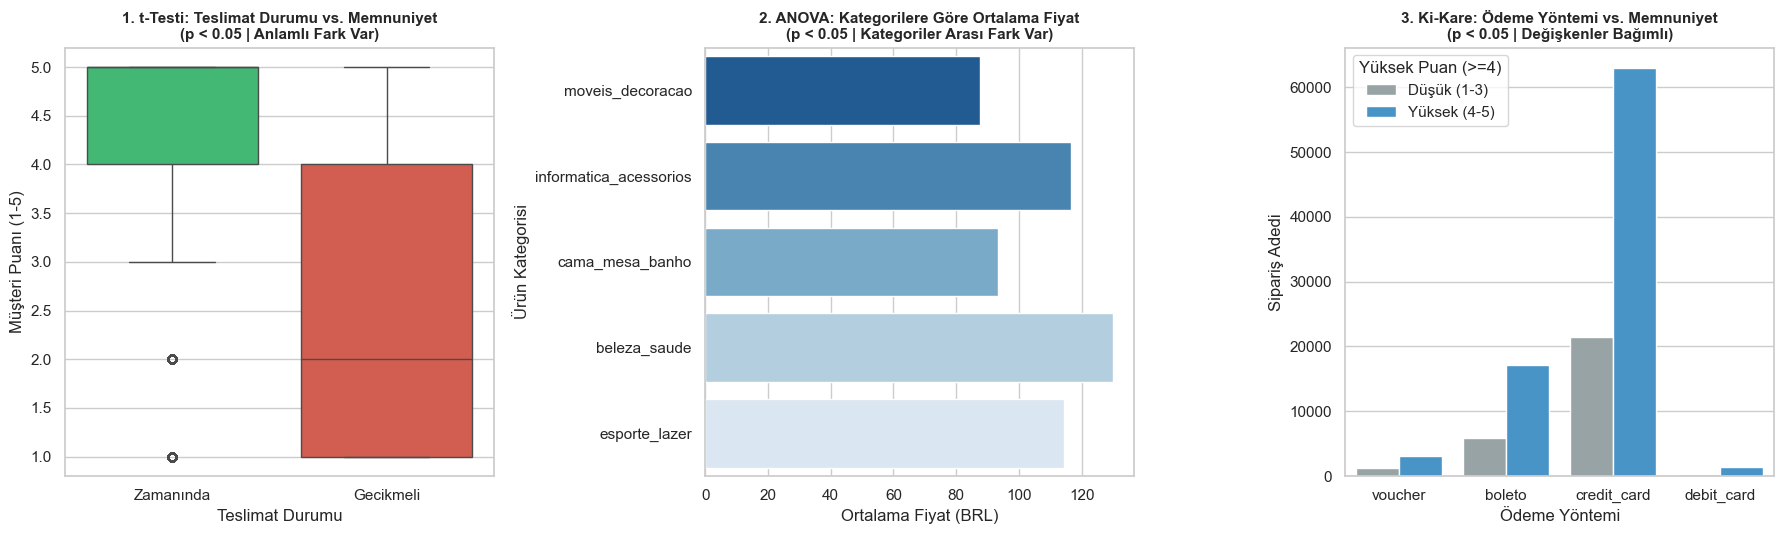

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ====================================================
# 1. ÖDEME VE REVIEWS TEKİLLEŞTİRME (Voucher Öncelikli)
# ====================================================
# Kupon (voucher) kullanımını kaybetmemek için sıralayıp tekilleştiriyoruz
payment_sorted = payment.sort_values(by=['order_id', 'payment_type'], ascending=[True, False])
payment_unique = payment_sorted.drop_duplicates(subset=['order_id'], keep='first')
reviews_unique = reviews.drop_duplicates(subset=['order_id'], keep='first')

# ====================================================
# 2. DF_MASTER BİRLEŞTİRME
# ====================================================
df_master = (
    dataset
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews_unique, on='order_id', how='left')
)

# ====================================================
# 3. TÜRETİLMİŞ SÜTUNLARIN HESAPLANMASI
# ====================================================
# Tarih sütunlarını datetime formatına çevirme
df_master['order_delivered_customer_date'] = pd.to_datetime(df_master['order_delivered_customer_date'])
df_master['order_estimated_delivery_date'] = pd.to_datetime(df_master['order_estimated_delivery_date'])

# Gecikme günü hesabı
df_master['gecikme_gun'] = (
    df_master['order_delivered_customer_date'] - df_master['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

# Teslimat durumu sütunu
df_master['teslimat_durumu'] = df_master['gecikme_gun'].apply(
    lambda x: 'Gecikmeli' if x > 0 else 'Zamanında'
)

# Yüksek memnuniyet sütunu (4 ve 5 alanlar)
df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4

# ====================================================
# 4. GÖRSELLEŞTİRME (3 PANELLİ GRAFİK)
# ====================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. GRAFİK: t-Testi Görseli (Teslimat Durumu vs. Memnuniyet)
sns.boxplot(
    x='teslimat_durumu', 
    y='review_score', 
    data=df_master, 
    hue='teslimat_durumu',
    palette=['#2ecc71', '#e74c3c'], 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('1. t-Testi: Teslimat Durumu vs. Memnuniyet\n(p < 0.05 | Anlamlı Fark Var)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Teslimat Durumu')
axes[0].set_ylabel('Müşteri Puanı (1-5)')

# 2. GRAFİK: ANOVA Görseli (Kategori vs. Ortalama Fiyat)
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
df_top5 = df_master[df_master['product_category_name'].isin(top_5_cats)]

sns.barplot(
    x='price', 
    y='product_category_name', 
    data=df_top5, 
    estimator=np.mean, 
    errorbar=None, 
    hue='product_category_name',
    palette='Blues_r', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('2. ANOVA: Kategorilere Göre Ortalama Fiyat\n(p < 0.05 | Kategoriler Arası Fark Var)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

# 3. GRAFİK: Ki-Kare Görseli (Ödeme Yöntemi vs. Memnuniyet Oranı)
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])].copy()

sns.countplot(
    x='payment_type', 
    hue='yuksek_memnuniyet', 
    data=sub_df, 
    palette=['#95a5a6', '#3498db'], 
    ax=axes[2]
)
axes[2].set_title('3. Ki-Kare: Ödeme Yöntemi vs. Memnuniyet\n(p < 0.05 | Değişkenler Bağımlı)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Sipariş Adedi')
axes[2].legend(title='Yüksek Puan (>=4)', labels=['Düşük (1-3)', 'Yüksek (4-5)'])

plt.tight_layout()
plt.savefig('slayt_3_hipotez_testleri.png', dpi=300)
plt.show()